# Escalado
Conjunto de datos: iris (incluido en sklearn)

Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [8]:
# Importar librerías necesarias
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
# Cargar el conjunto de datos
iris = load_iris(as_frame=True)
data = iris.data

In [10]:
# Visualizar las estadísticas iniciales
print("Estadísticas iniciales:")
data.describe()

Estadísticas iniciales:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [11]:
# Aplicar MinMaxScaler
minmax_scaler = MinMaxScaler()
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [12]:
# Aplicar StandardScaler
standard_scaler = StandardScaler()
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


In [13]:
comparacion = pd.concat(
    {'Original': data.describe(), 'MinMax': data_minmax.describe()},
    axis=1,
)
comparacion.round(3)

Original                                                      \
      sepal length (cm) sepal width (cm) petal length (cm) petal width (cm)   
count           150.000          150.000           150.000          150.000   
mean              5.843            3.057             3.758            1.199   
std               0.828            0.436             1.765            0.762   
min               4.300            2.000             1.000            0.100   
25%               5.100            2.800             1.600            0.300   
50%               5.800            3.000             4.350            1.300   
75%               6.400            3.300             5.100            1.800   
max               7.900            4.400             6.900            2.500   

                 MinMax                                                      
      sepal length (cm) sepal width (cm) petal length (cm) petal width (cm)  
count           150.000          150.000           150.000          150.000  
mean              0.429            0.441             0.467            0.458  
std               0.230            0.182             0.299            0.318  
min               0.000            0.000             0.000            0.000  
25%               0.222            0.333             0.102            0.083  
50%               0.417            0.417             0.568            0.500  
75%               0.583            0.542             0.695            0.708  
max               1.000            1.000             1.000            1.000

**Respuesta:** en los datos originales cada variable tiene su propia escala (por ejemplo `sepal length` va de 4.3 a 7.9 y `petal width` de 0.1 a 2.5, con medias y desviaciones distintas). Tras el escalado MinMax **todas** las variables tienen mínimo 0 y máximo 1; las medias y desviaciones quedan en rangos comparables, pero la forma de la distribución no cambia (solo se reescala linealmente).

### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

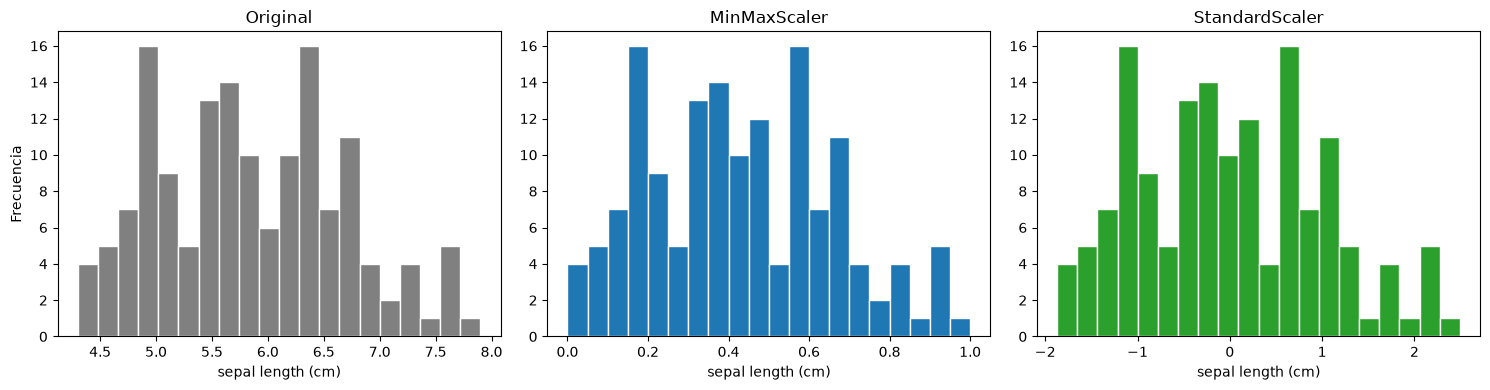

In [14]:
col = 'sepal length (cm)'
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(data[col], bins=20, color='gray', edgecolor='white')
axes[0].set_title('Original')

axes[1].hist(data_minmax[col], bins=20, color='tab:blue', edgecolor='white')
axes[1].set_title('MinMaxScaler')

axes[2].hist(data_standard[col], bins=20, color='tab:green', edgecolor='white')
axes[2].set_title('StandardScaler')

for ax in axes:
    ax.set_xlabel(col)
axes[0].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

La forma de la distribución es idéntica en las tres gráficas; solo cambia el eje x (original: 4.3–7.9, MinMax: 0–1, Standard: centrada en 0 con desviación 1).

### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

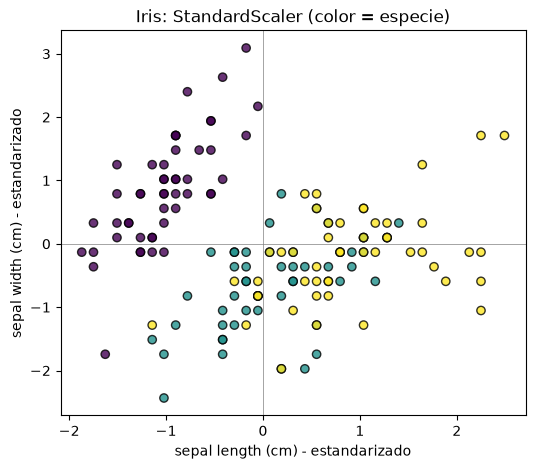

In [15]:
plt.figure(figsize=(6, 5))
plt.scatter(data_standard['sepal length (cm)'], data_standard['sepal width (cm)'],
            c=iris.target, cmap='viridis', edgecolor='k', alpha=0.8)
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.xlabel('sepal length (cm) - estandarizado')
plt.ylabel('sepal width (cm) - estandarizado')
plt.title('Iris: StandardScaler (color = especie)')
plt.show()

### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

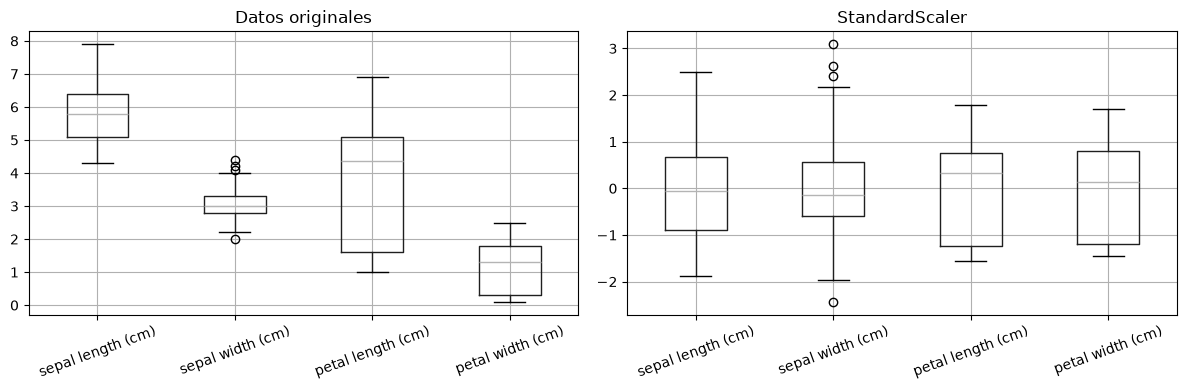

Media tras StandardScaler:
 sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
Desv. estándar tras StandardScaler:
 sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0


In [16]:
# Evidencia: ¿hay valores atípicos que justifiquen preferir una técnica sobre otra?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data.boxplot(ax=axes[0], rot=20)
axes[0].set_title('Datos originales')
data_standard.boxplot(ax=axes[1], rot=20)
axes[1].set_title('StandardScaler')
plt.tight_layout()
plt.show()

print("Media tras StandardScaler:\n", data_standard.mean().round(6).to_string())
print("Desv. estándar tras StandardScaler:\n", data_standard.std(ddof=0).round(6).to_string())

**Respuesta:** para iris recomendaría **StandardScaler**. Las variables están en las mismas unidades (cm) pero con varianzas distintas, y casi no hay valores atípicos (solo unos pocos puntos en `sepal width`), por lo que la media y la desviación estándar son estadísticos confiables. Además, la mayoría de los algoritmos habituales sobre este conjunto (KNN, SVM, regresión logística, PCA) funcionan mejor con datos centrados y de varianza unitaria. MinMaxScaler también sería aceptable aquí, pero es más sensible a outliers porque depende del mínimo y el máximo, y es preferible cuando se necesita un rango acotado [0, 1] (p. ej. redes neuronales con ciertas activaciones o procesamiento de imágenes).